In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RepeatedKFold, cross_validate
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.base import clone

RANDOM_STATE = 42

In [2]:
df = pd.read_excel("100_Disasters.xlsx", sheet_name="Data_030520")

target = "SocietySpeed - Months"
df = df.dropna(subset=[target]).copy()
df[target] = pd.to_numeric(df[target], errors="coerce")
df = df.dropna(subset=[target]).copy()

print("Dataset shape:", df.shape)
print("Records with a known recovery-time target:", len(df))
print("\nRecovery-time summary (months):")
display(df[target].describe().to_frame())
print("Unique target values:", df[target].nunique())
print("Target skewness:", round(df[target].skew(), 2))
print("\nRecovery-time frequencies:")
display(df[target].value_counts().sort_index().rename_axis("Months").to_frame("Records"))

Dataset shape: (100, 62)
Records with a known recovery-time target: 100

Recovery-time summary (months):


,SocietySpeed - Months
count,100.000000
mean,52.130000
std,52.354012
min,1.000000
25%,18.000000
50%,36.000000
75%,75.000000
max,300.000000


Unique target values: 17
Target skewness: 1.92

Recovery-time frequencies:


,Records
Months,
1.0,2
3.0,1
6.0,4
9.0,8
12.0,3
18.0,24
36.0,19
48.0,8
60.0,4


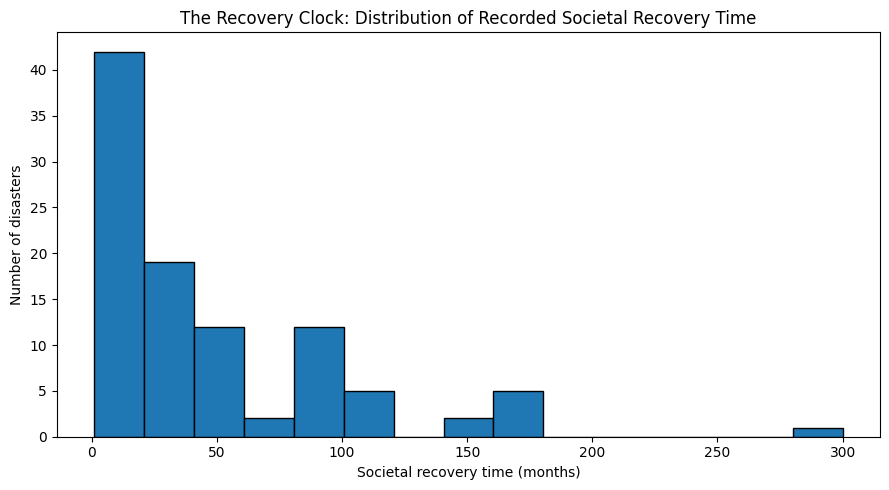

Median recovery time: 36.0 months


In [3]:
plt.figure(figsize=(9, 5))
plt.hist(df[target], bins=15, edgecolor="black")
plt.xlabel("Societal recovery time (months)")
plt.ylabel("Number of disasters")
plt.title("The Recovery Clock: Distribution of Recorded Societal Recovery Time")
plt.tight_layout()
plt.show()

print(f"Median recovery time: {df[target].median():.1f} months")

In [4]:
numeric_features = [
    "Year",
    "Population",
    "GDP per Capita",
    "Economic Loss",
    "Fatalities",
    "Displaced",
    "Affected Population",
    "Proportion Population Affected",
]

categorical_features = [
    "Disaster Type",
    "Disaster Subtype",
    "Scale",
    "Income Group",
    "Preparedness",
    "Public Participation",
    "Decision Making",
]

features = numeric_features + categorical_features
missing_columns = [col for col in features + [target] if col not in df.columns]
if missing_columns:
    raise KeyError(f"Expected columns not found in dataset: {missing_columns}")

X = df[features].copy()
y = df[target].copy()

for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

print("Number of input features:", len(features))
print("Number of records:", len(X))
print("\nMissing values per selected feature:")
display(X.isna().sum().sort_values(ascending=False).to_frame("Missing values"))
print("\nMissing-value percentage per feature:")
display((X.isna().mean() * 100).sort_values(ascending=False).round(1).to_frame("Missing %"))

Number of input features: 15
Number of records: 100

Missing values per selected feature:


,Missing values
Displaced,38
Affected Population,16
Proportion Population Affected,12
Economic Loss,6
GDP per Capita,2
Population,0
Year,0
Fatalities,0
Disaster Type,0
Disaster Subtype,0



Missing-value percentage per feature:


,Missing %
Displaced,38.0
Affected Population,16.0
Proportion Population Affected,12.0
Economic Loss,6.0
GDP per Capita,2.0
Population,0.0
Year,0.0
Fatalities,0.0
Disaster Type,0.0
Disaster Subtype,0.0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))
print("Training target median:", y_train.median(), "months")

Training records: 80
Test records: 20
Training target median: 36.0 months


In [6]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

def make_random_forest():
    return Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            n_estimators=300,
            max_depth=4,
            min_samples_leaf=3,
            random_state=RANDOM_STATE,
        )),
    ])

rf_original = make_random_forest()

In [7]:
cv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

cv_models = {
    "Median Baseline": DummyRegressor(strategy="median"),
    "Linear Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LinearRegression()),
    ]),
    "Random Forest": make_random_forest(),
    "Random Forest (log target)": TransformedTargetRegressor(
        regressor=make_random_forest(),
        func=np.log1p,
        inverse_func=np.expm1,
    ),
}

cv_rows = []
for name, model in cv_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2",
        },
        n_jobs=1,
    )
    cv_rows.append({
        "Model": name,
        "Mean MAE (months)": -scores["test_mae"].mean(),
        "MAE Std": scores["test_mae"].std(),
        "Mean RMSE (months)": -scores["test_rmse"].mean(),
        "Mean R2": scores["test_r2"].mean(),
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values("Mean MAE (months)")
display(cv_results_df.round(2))

,Model,Mean MAE (months),MAE Std,Mean RMSE (months),Mean R2
3,Random Forest (log target),29.20,12.11,43.80,0.23
2,Random Forest,31.22,8.93,43.10,0.18
0,Median Baseline,36.88,14.29,52.94,-0.14
1,Linear Regression,47.21,17.70,76.89,-1.92


In [8]:
rf_original.fit(X_train, y_train)
y_pred = rf_original.predict(X_test)

rf_mae = mean_absolute_error(y_test, y_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rf_r2 = r2_score(y_test, y_pred)

print("FINAL RANDOM FOREST TEST EVALUATION")
print("-" * 42)
print(f"Test records: {len(y_test)}")
print(f"MAE:  {rf_mae:.2f} months")
print(f"RMSE: {rf_rmse:.2f} months")
print(f"R²:   {rf_r2:.3f}")

FINAL RANDOM FOREST TEST EVALUATION
------------------------------------------
Test records: 20
MAE:  20.44 months
RMSE: 27.28 months
R²:   0.570


In [9]:
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

baseline_mae = mean_absolute_error(y_test, baseline_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_r2 = r2_score(y_test, baseline_pred)

model_comparison_df = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE_months": rf_mae,
        "RMSE_months": rf_rmse,
        "R2": rf_r2,
    },
    {
        "Model": "Median Baseline",
        "MAE_months": baseline_mae,
        "RMSE_months": baseline_rmse,
        "R2": baseline_r2,
    },
])

display(model_comparison_df.round(3))
mae_improvement = (baseline_mae - rf_mae) / baseline_mae * 100
print(f"MAE reduction relative to the median baseline: {mae_improvement:.1f}%")

,Model,MAE_months,RMSE_months,R2
0,Random Forest,20.444,27.283,0.570
1,Median Baseline,29.250,45.165,-0.178


MAE reduction relative to the median baseline: 30.1%


In [10]:
test_results = pd.DataFrame({
    "Actual_Months": y_test,
    "Predicted_Months": y_pred,
}, index=X_test.index)
test_results["Absolute_Error_Months"] = (
    test_results["Actual_Months"] - test_results["Predicted_Months"]
).abs()

display(test_results.round(2))

,Actual_Months,Predicted_Months,Absolute_Error_Months
86,180.0,127.30,52.70
54,48.0,79.99,31.99
72,48.0,63.19,15.19
46,18.0,18.62,0.62
45,36.0,21.38,14.62
40,36.0,21.24,14.76
22,18.0,28.42,10.42
83,96.0,119.55,23.55
10,60.0,81.15,21.15
0,9.0,23.12,14.12


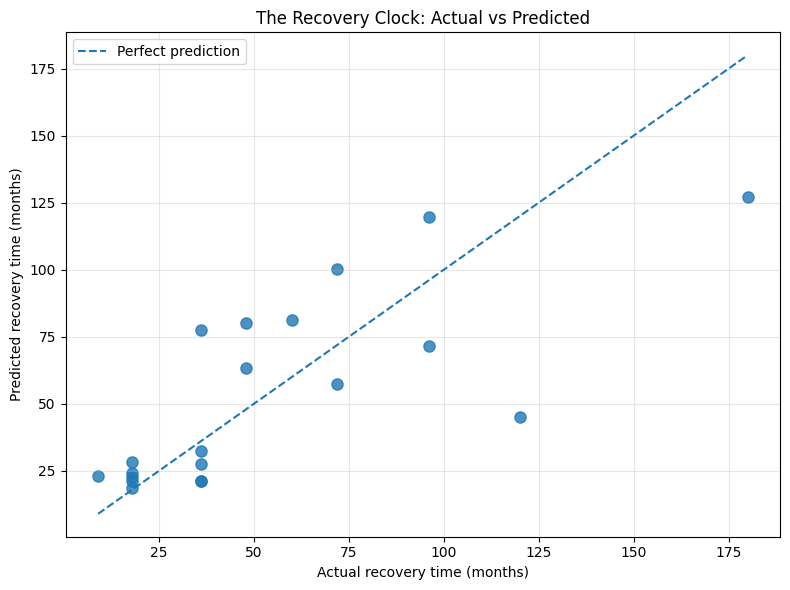

In [11]:
actual = np.asarray(y_test)
predicted = np.asarray(y_pred)

plt.figure(figsize=(8, 6))
plt.scatter(actual, predicted, s=65, alpha=0.8)
lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())
plt.plot([lower, upper], [lower, upper], linestyle="--", label="Perfect prediction")
plt.xlabel("Actual recovery time (months)")
plt.ylabel("Predicted recovery time (months)")
plt.title("The Recovery Clock: Actual vs Predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,Feature,Importance,Std
0,Fatalities,11.398,4.079
1,Disaster Subtype,2.229,0.991
2,Disaster Type,1.587,0.690
3,Income Group,1.239,0.174
4,Year,1.018,0.539
5,Economic Loss,0.404,0.104
6,Population,0.375,0.362
7,Displaced,0.284,0.663
8,Affected Population,0.230,0.245
9,Proportion Population Affected,0.149,0.160


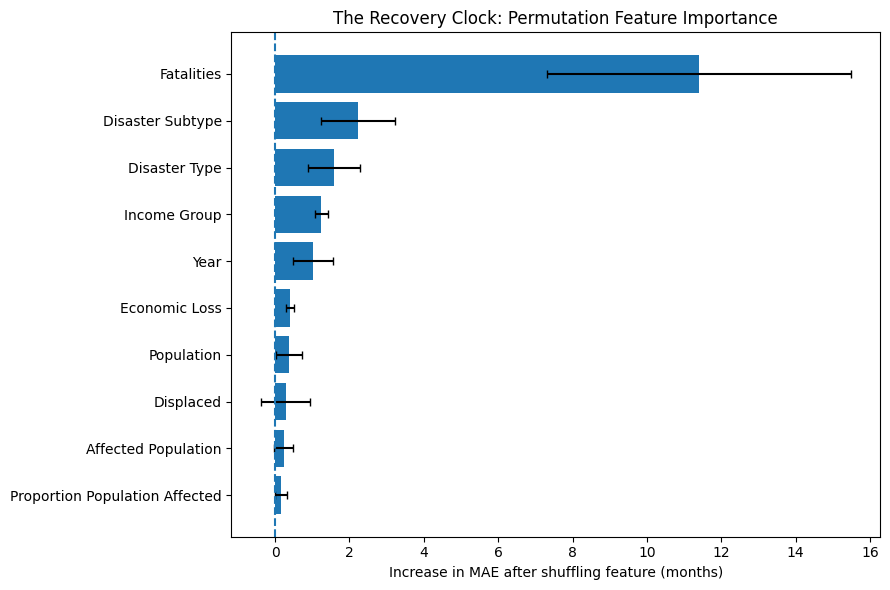

In [12]:
importance_result = permutation_importance(
    rf_original,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Std": importance_result.importances_std,
}).sort_values("Importance", ascending=False).reset_index(drop=True)

display(importance_df.round(3))

top_features = importance_df.head(10).sort_values("Importance")
plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"], xerr=top_features["Std"], capsize=3)
plt.axvline(0, linestyle="--")
plt.xlabel("Increase in MAE after shuffling feature (months)")
plt.title("The Recovery Clock: Permutation Feature Importance")
plt.tight_layout()
plt.show()

In [13]:
model_comparison_df.to_csv("model_comparison.csv", index=False)
importance_df.to_csv("feature_importance.csv", index=False)
cv_results_df.to_csv("cross_validation_results.csv", index=False)
test_results.to_csv("test_predictions.csv", index=True)

print("Saved files:")
print("- model_comparison.csv")
print("- feature_importance.csv")
print("- cross_validation_results.csv")
print("- test_predictions.csv")

Saved files:
- model_comparison.csv
- feature_importance.csv
- cross_validation_results.csv
- test_predictions.csv


In [14]:
idx = X_test.index[0]
actual_one = float(y_test.loc[idx])
predicted_one = float(rf_original.predict(X_test.loc[[idx]])[0])

print("HELD-OUT HISTORICAL DISASTER")
print("-" * 35)
print("Disaster type:", df.loc[idx, "Disaster Type"])
print("Disaster subtype:", df.loc[idx, "Disaster Subtype"])
print("Year:", df.loc[idx, "Year"])
print(f"Actual recovery time: {actual_one:.1f} months")
print(f"Predicted recovery time: {predicted_one:.1f} months")
print(f"Absolute error: {abs(actual_one - predicted_one):.1f} months")

HELD-OUT HISTORICAL DISASTER
-----------------------------------
Disaster type: Earthquake
Disaster subtype: Earthquake
Year: 1990
Actual recovery time: 180.0 months
Predicted recovery time: 127.3 months
Absolute error: 52.7 months


In [15]:
import ipywidgets as widgets
from IPython.display import display, clear_output

fields = {}

for col in numeric_features:
    vals = pd.to_numeric(X_train[col], errors="coerce")
    default = vals.median()
    if pd.isna(default):
        default = 0.0
    fields[col] = widgets.FloatText(
        value=float(default),
        description=col,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="520px"),
    )

for col in categorical_features:
    values = X_train[col].dropna().unique().tolist()
    options = [(str(v), v) for v in values]
    if not options:
        options = [("Unknown", "Unknown")]
    fields[col] = widgets.Dropdown(
        options=options,
        value=options[0][1],
        description=col,
        style={"description_width": "initial"},
        layout=widgets.Layout(width="520px"),
    )

button = widgets.Button(description="Estimate Recovery Time", button_style="primary", icon="calculator")
output = widgets.Output()

def estimate_recovery(_):
    with output:
        clear_output()
        row = {col: widget.value for col, widget in fields.items()}
        sample = pd.DataFrame([row], columns=features)
        try:
            prediction = max(0.0, float(rf_original.predict(sample)[0]))
            median = float(y_train.median())
            difference = prediction - median

            print("=" * 48)
            print("THE RECOVERY CLOCK")
            print("=" * 48)
            print(f"Estimated societal recovery time: {prediction:.1f} months")
            print(f"Approximately {prediction / 12:.1f} years")
            print(f"Historical training-set median: {median:.1f} months")
            if difference > 0:
                print(f"Estimate is {difference:.1f} months above the median.")
            elif difference < 0:
                print(f"Estimate is {abs(difference):.1f} months below the median.")
            else:
                print("Estimate equals the training-set median.")

            print("\nTop overall permutation-importance features:")
            for _, item in importance_df.head(3).iterrows():
                print(f"- {item['Feature']}: {item['Importance']:.3f}")

            print("\nLimitations:")
            print("- This is an estimate, not a guaranteed timeline.")
            print("- It predicts recorded societal recovery time, not daily mobility recovery.")
            print("- The model was trained on only 100 labelled disasters.")
            print("- Feature importance is not proof of causation.")
            print("- Use local assessments and expert judgment.")
        except Exception as error:
            print("Prediction failed:", error)

button.on_click(estimate_recovery)
display(widgets.VBox([
    widgets.HTML("<h2>The Recovery Clock</h2><p>Enter disaster characteristics to estimate recorded societal recovery time.</p>"),
    *fields.values(), button, output,
]))